# TP DES & AES — Partie 6 : attaque par analyse de fréquences

Texte utilisé : *Alice's Adventures in Wonderland* (Lewis Carroll, domaine public, Projet Gutenberg), ~144 ko de texte anglais. Le fichier `alice.txt` doit être dans le même dossier que le notebook.

Plan :
1. Chiffrement de César → attaque par fréquences des lettres
2. (bonus) Substitution mono-alphabétique quelconque → même attaque
3. Chiffrement DES du même texte → même attaque

In [1]:
%run ./02_DES.ipynb

K+ (PC-1)   : 1111000 0110011 0010101 0101111 0101010 1011001 1001111 0001111
K1 (PC-2)   : 000110 110000 001011 101111 111111 000111 000001 110010
IP(M)       : 11001100 00000000 11001100 11111111 11110000 10101010 11110000 10101010
E(R0)       : 011110 100001 010101 010101 011110 100001 010101 010101
E(R0)^K1    : 011000 010001 011110 111010 100001 100110 010100 100111
S-box       : 0101 1100 1000 0010 1011 0101 1001 0111
f(R0,K1)    : 0010 0011 0100 1010 1010 1001 1011 1011

chiffré (version rapide)  : 85E813540F0AB405
chiffré (version simple)  : 85E813540F0AB405
déchiffré                 : 0123456789ABCDEF
226dfab1f7a734470847d2f299d2879f04d5aa1fed53b03e44c642e93128e87441282b5087761b61
b'Data Encryption Standard - TP 5IF'


In [2]:
import os, random, math, string
from collections import Counter
import matplotlib.pyplot as plt

random.seed(1)
text = open("alice.txt", encoding="utf-8").read()
print(len(text), "caractères")
print(text[:300])

144395 caractères
[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversatio


Fréquences de référence des lettres en anglais (en %) :

In [3]:
ENGLISH = {'a':8.167,'b':1.492,'c':2.782,'d':4.253,'e':12.702,'f':2.228,'g':2.015,'h':6.094,
           'i':6.966,'j':0.153,'k':0.772,'l':4.025,'m':2.406,'n':6.749,'o':7.507,'p':1.929,
           'q':0.095,'r':5.987,'s':6.327,'t':9.056,'u':2.758,'v':0.978,'w':2.360,'x':0.150,
           'y':1.974,'z':0.074}
LETTERS = string.ascii_lowercase

def letter_freq(s):
    c = Counter(ch for ch in s.lower() if ch in LETTERS)
    n = sum(c.values())
    return {l: 100 * c[l] / n for l in LETTERS}

## 1. Chiffrement de César

Chaque lettre est décalée de $k$ positions dans l'alphabet. On choisit une clé au hasard (inconnue de l'attaquant).

In [4]:
def caesar(s, k):
    out = []
    for ch in s:
        if ch.islower():   out.append(chr((ord(ch) - 97 + k) % 26 + 97))
        elif ch.isupper(): out.append(chr((ord(ch) - 65 + k) % 26 + 65))
        else:              out.append(ch)
    return ''.join(out)

secret_k = random.randint(1, 25)
ct_caesar = caesar(text, secret_k)
print(ct_caesar[:300])

[Fqnhj'x Fiajsyzwjx ns Btsijwqfsi gd Qjbnx Hfwwtqq 1865]

HMFUYJW N. Itbs ymj Wfggny-Mtqj

Fqnhj bfx gjlnssnsl yt ljy ajwd ynwji tk xnyynsl gd mjw xnxyjw ts ymj
gfsp, fsi tk mfansl stymnsl yt it: tshj tw ybnhj xmj mfi ujjuji nsyt ymj
gttp mjw xnxyjw bfx wjfinsl, gzy ny mfi st unhyzwjx tw htsajwxfynt


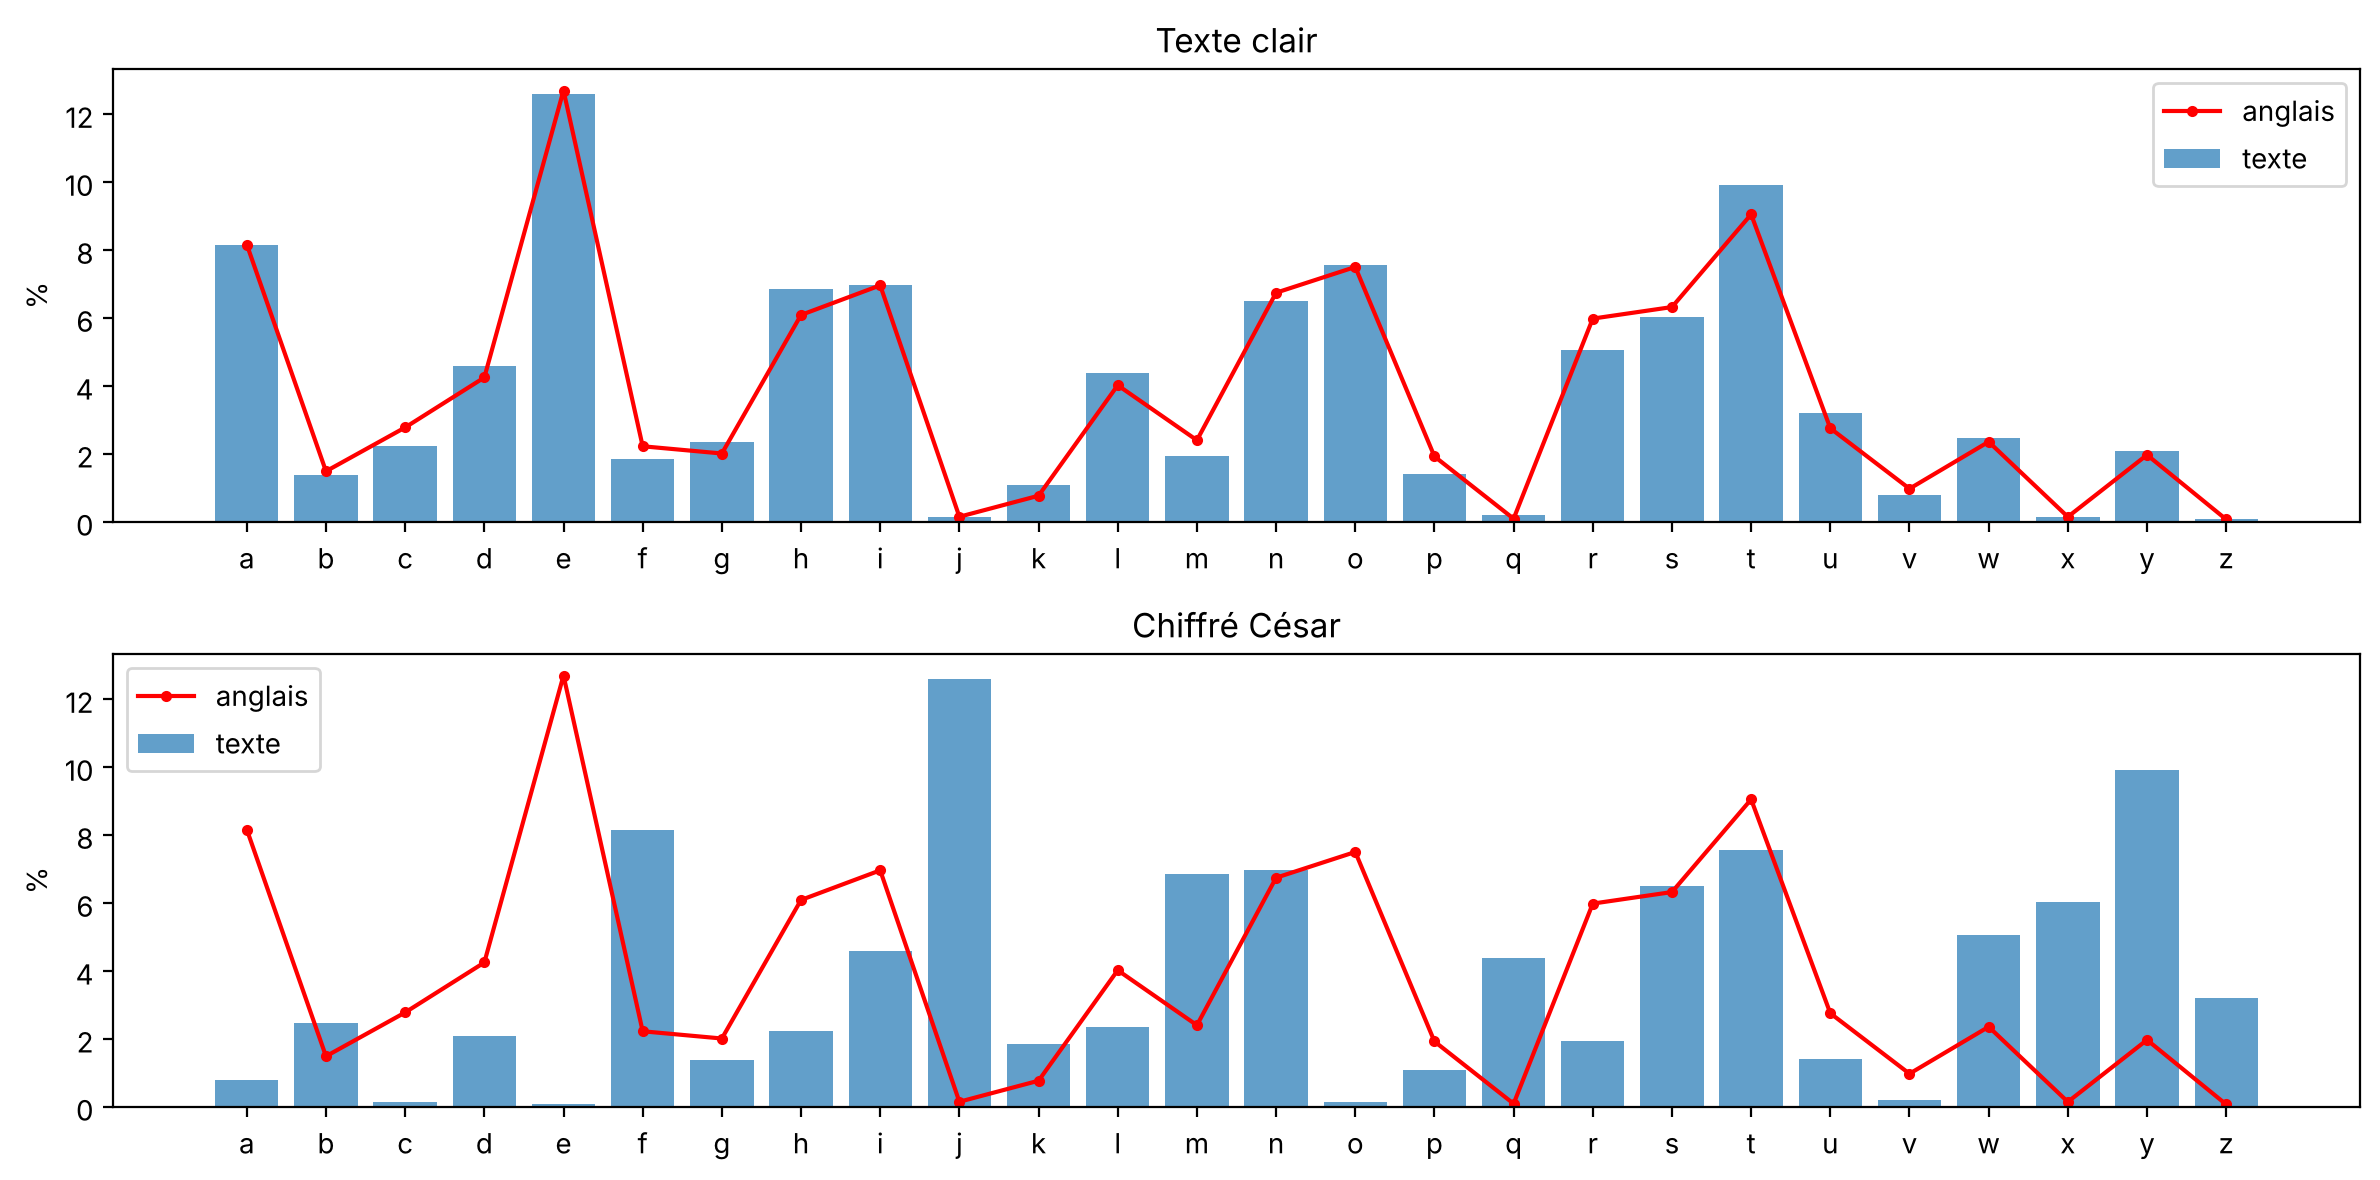

In [5]:
def plot_freq(freqs, title, ax):
    ax.bar(range(26), [freqs[l] for l in LETTERS], alpha=.7, label="texte")
    ax.plot(range(26), [ENGLISH[l] for l in LETTERS], "r.-", label="anglais")
    ax.set_xticks(range(26)); ax.set_xticklabels(list(LETTERS))
    ax.set_ylabel("%"); ax.set_title(title); ax.legend()

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
plot_freq(letter_freq(text), "Texte clair", ax[0])
plot_freq(letter_freq(ct_caesar), "Chiffré César", ax[1])
plt.tight_layout(); plt.show()

On voit que l'histogramme du chiffré est **le même que celui du clair, simplement décalé**. César ne fait que renommer les lettres, la distribution est conservée.

**Attaque** : pour chaque décalage possible $k$ (26 possibilités), on déchiffre et on calcule la distance du $\chi^2$ entre les fréquences obtenues et celles de l'anglais. Le bon $k$ est celui qui minimise le $\chi^2$.

$$\chi^2(k) = \sum_{l} \frac{(f_l^{(k)} - E_l)^2}{E_l}$$

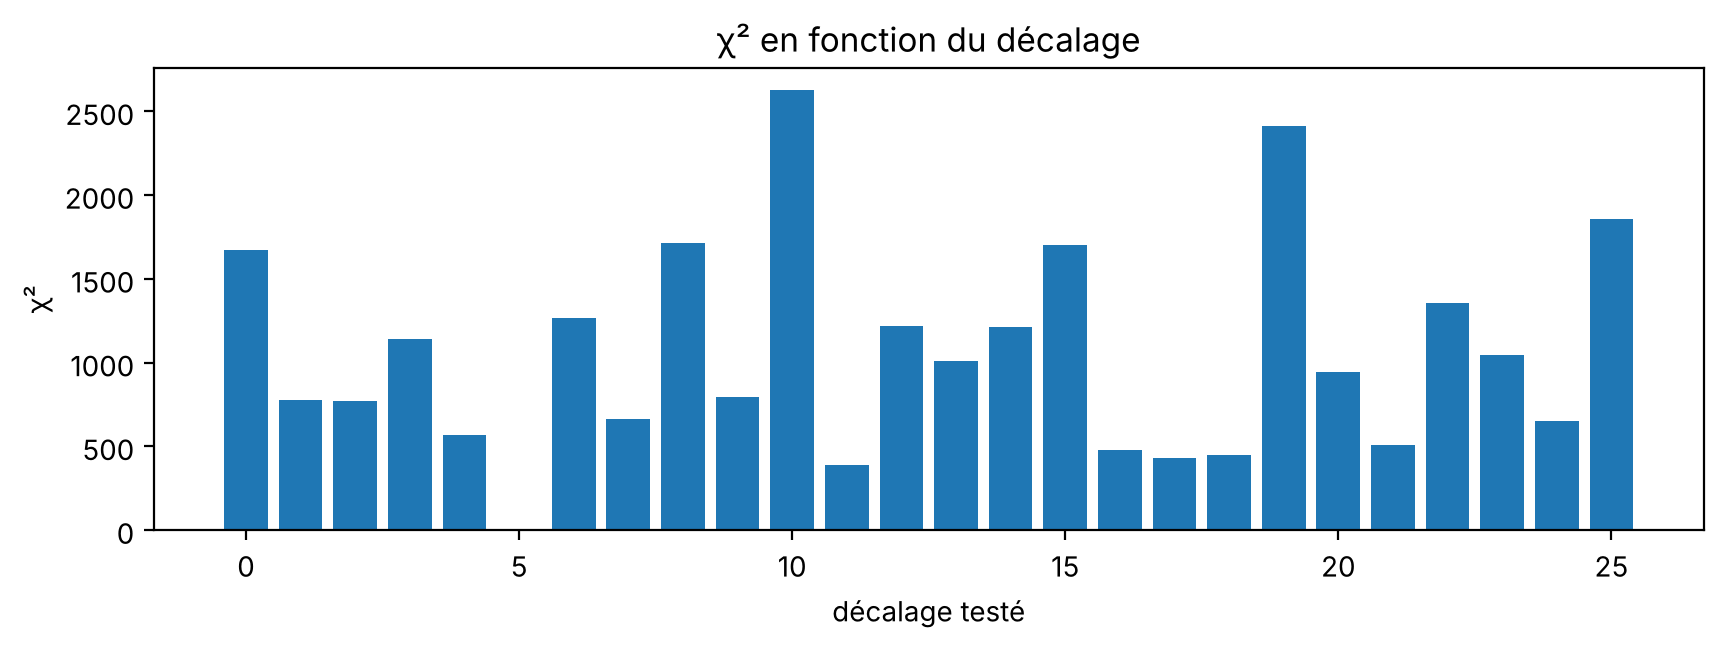

clé secrète : 5 | clé trouvée : 5
texte retrouvé à l'identique : True
[Alice's Adventures in Wonderland by Lewis Carroll 1865]

CHAPTER I. Down the Rabbit-Hole

Alice was beginning to get very tired of sitting by her sister on the
bank, and of having nothing to do: once or twice she had peeped into the
book her sister was reading, but it had no pictures or conversatio


In [6]:
def chi2(freqs):
    return sum((freqs[l] - ENGLISH[l]) ** 2 / ENGLISH[l] for l in LETTERS)

scores = [chi2(letter_freq(caesar(ct_caesar, -k))) for k in range(26)]
k_found = scores.index(min(scores))

plt.figure(figsize=(10, 3))
plt.bar(range(26), scores); plt.xlabel("décalage testé"); plt.ylabel("χ²")
plt.title("χ² en fonction du décalage"); plt.show()

print("clé secrète :", secret_k, "| clé trouvée :", k_found)
recovered = caesar(ct_caesar, -k_found)
print("texte retrouvé à l'identique :", recovered == text)
print(recovered[:300])

L'attaque retrouve la clé immédiatement et **100 % du texte** est récupéré. Même la méthode naïve « la lettre la plus fréquente du chiffré correspond au `e` » suffit ici :

In [7]:
fr = letter_freq(ct_caesar)
most = max(fr, key=fr.get)
print("lettre la plus fréquente :", most, "-> décalage =", (ord(most) - ord('e')) % 26)

lettre la plus fréquente : j -> décalage = 5


## 2. Bonus : substitution mono-alphabétique quelconque

César n'a que 25 clés (on pourrait même tout tester à la main). Avec une permutation quelconque de l'alphabet, il y a $26! \approx 4\cdot 10^{26}$ clés, la force brute est impossible. Mais l'analyse de fréquences marche quand même : on associe la $i$-ème lettre la plus fréquente du chiffré à la $i$-ème lettre la plus fréquente en anglais.

In [8]:
perm = list(LETTERS); random.shuffle(perm)
sub_key = dict(zip(LETTERS, perm))

def substitute(s, mapping):
    out = []
    for ch in s:
        lo = ch.lower()
        if lo in mapping:
            c = mapping[lo]
            out.append(c.upper() if ch.isupper() else c)
        else:
            out.append(ch)
    return ''.join(out)

ct_sub = substitute(text, sub_key)

# attaque : classement par fréquences
fr = letter_freq(ct_sub)
cipher_rank = sorted(LETTERS, key=lambda l: -fr[l])
english_rank = sorted(LETTERS, key=lambda l: -ENGLISH[l])
guess = dict(zip(cipher_rank, english_rank))
attempt = substitute(ct_sub, guess)

inv_key = {v: k for k, v in sub_key.items()}
good_letters = sum(guess[c] == inv_key[c] for c in LETTERS)
letters_txt = [(a, b) for a, b in zip(attempt.lower(), text.lower()) if a in LETTERS]
pct = 100 * sum(a == b for a, b in letters_txt) / len(letters_txt)

print(f"lettres de l'alphabet correctement retrouvées : {good_letters}/26")
print(f"proportion des lettres du texte correctement déchiffrées : {pct:.1f} %")
print()
print(attempt[1000:1400])

lettres de l'alphabet correctement retrouvées : 12/26
proportion des lettres du texte correctement déchiffrées : 62.2 %

 unes tne Rabbit awtcallf TOOV A UATWN
OCT OY ITH UAIHTWOAT-POWVET, asd looved at it, asd tnes ncrried os,
Aliwe htarted to ner yeet, yor it ylahned awrohh ner gisd tnat hne nad
seker beyore hees a rabbit uitn eitner a uaihtwoat-powvet, or a uatwn
to tave oct oy it, asd bcrsism uitn wcriohitf, hne ras awrohh tne yield
ayter it, asd yortcsatelf uah qcht is tige to hee it pop dous a larme
rabbit-nol


Avec uniquement le classement des fréquences, on ne retrouve qu'une partie de l'alphabet, mais la majorité des lettres du texte (les lettres très fréquentes comme `e`, `t`, `a`, `o` sont souvent bien placées, les lettres de fréquences proches sont inversées). La **structure du texte reste entièrement visible** : espaces, ponctuation, longueur des mots, majuscules, mots répétés (« the », « and », « Alice »). Un attaquant finit facilement le travail à la main ou avec les fréquences de bigrammes (`th`, `he`, `in`…).

## 3. Chiffrement DES du même texte

On chiffre le texte (encodé en octets) avec DES en mode ECB et notre implémentation.

In [9]:
pt_bytes = text.encode("utf-8")
key = os.urandom(8)
ct_des = des_encrypt(pt_bytes, key)
print(len(pt_bytes), "octets ->", len(ct_des), "octets chiffrés")
print(ct_des[:64].hex())

144395 octets -> 144400 octets chiffrés
a13af6503a27763b4fb6536540d57c1dc9cd3a465ff47fa97f664935d1ee47983fb14130a7dc6c60a0e11ce7d4ef5a8f4a9ad8c56b4c28930c7e586b4272a48a


Un chiffré DES n'est plus du texte : ce sont des octets quelconques (0–255). On refait donc l'analyse de fréquence **sur les octets** (c'est ce que verrait un attaquant), puis on essaie quand même l'analyse sur les « lettres ».

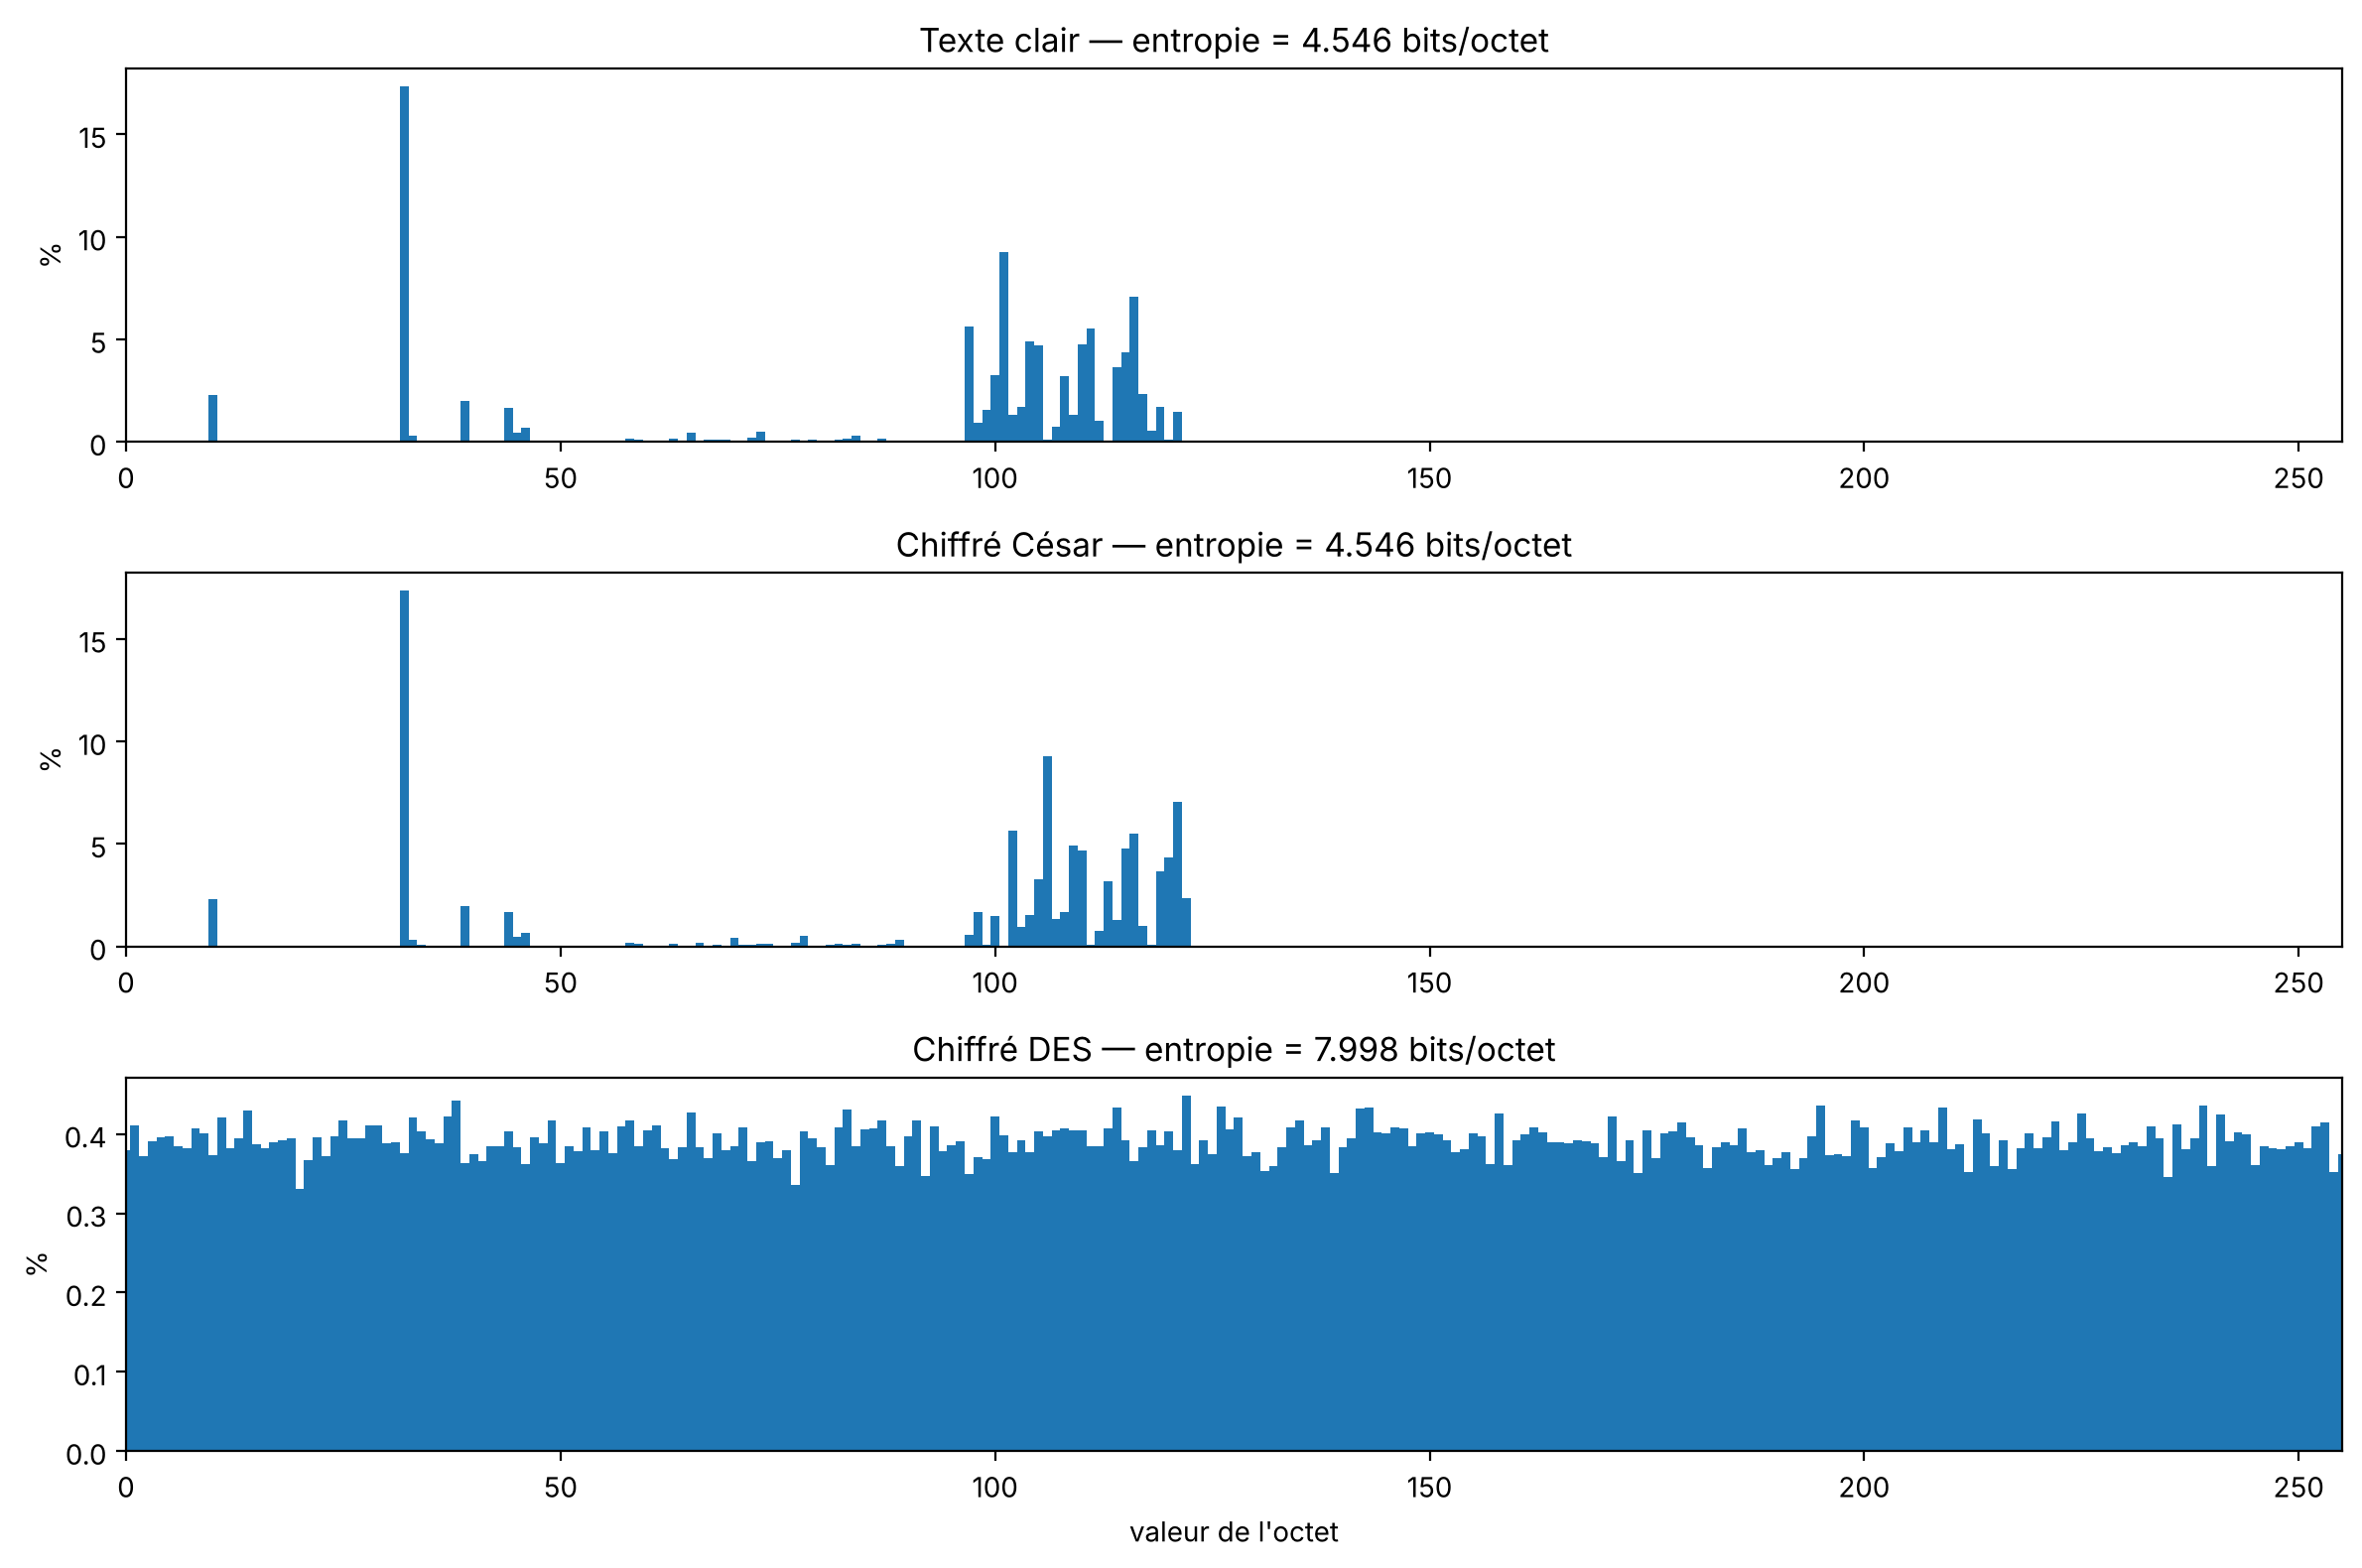

In [10]:
def byte_hist(b):
    c = Counter(b)
    return [100 * c[i] / len(b) for i in range(256)]

def entropy(b):
    c = Counter(b); n = len(b)
    return -sum(v / n * math.log2(v / n) for v in c.values())

fig, ax = plt.subplots(3, 1, figsize=(12, 8))
for a, data, title in [(ax[0], pt_bytes, "Texte clair"),
                       (ax[1], ct_caesar.encode(), "Chiffré César"),
                       (ax[2], ct_des, "Chiffré DES")]:
    a.bar(range(256), byte_hist(data), width=1)
    a.set_title(f"{title} — entropie = {entropy(data):.3f} bits/octet")
    a.set_xlim(0, 255); a.set_ylabel("%")
ax[2].set_xlabel("valeur de l'octet")
plt.tight_layout(); plt.show()

- Le clair et le César n'utilisent qu'une petite partie des 256 valeurs (lettres, espace, ponctuation) avec une distribution très déséquilibrée (l'espace et le `e` dominent) → entropie ≈ 4,5 bits/octet.
- Le chiffré DES utilise **toutes les valeurs de façon quasi uniforme** (~0,39 % chacune) → entropie proche du maximum de 8 bits/octet.

On tente quand même l'attaque « octet le plus fréquent = espace » et le classement par fréquences :

In [11]:
# octets ciphertext classés par fréquence vs octets du clair classés par fréquence
c_rank = [b for b, _ in Counter(ct_des).most_common()]
p_rank = [b for b, _ in Counter(pt_bytes).most_common()]
mapping = {c: p_rank[i] if i < len(p_rank) else 0x3F for i, c in enumerate(c_rank)}
attempt_des = bytes(mapping[b] for b in ct_des)
ok = sum(a == b for a, b in zip(attempt_des, pt_bytes)) / len(pt_bytes)
print(f"octets correctement retrouvés : {100 * ok:.2f} %")
print(attempt_des[1000:1300].decode("latin-1"))

print()
print("Fréquences des 5 octets les plus fréquents du chiffré DES (%) :",
      [round(100 * n / len(ct_des), 3) for _, n in Counter(ct_des).most_common(5)])

octets correctement retrouvés : 0.50 %
??d????????R?M??]? ?p?r??8???n)?????????????????k?????????????? ??W?fq???j?F??,U??5????l?5??Y?z?F?:????8?????????IGHy???*a:??1?[?G?F???ue????k:s?i?DF???w?N???Q?????mb?????c?z?Y???????F?z??a???l??1??????6??????????H??EBjQ????*1?????KG??1????????CX]????????X?T[qU?g??,?"?UT????b??D???S?Z??c?5?kR?????z?

Fréquences des 5 octets les plus fréquents du chiffré DES (%) : [0.449, 0.442, 0.436, 0.436, 0.435]


Même en donnant à l'attaquant la vraie distribution des octets du clair, la substitution par classement donne un texte illisible avec moins de 1 % d'octets corrects, ce qui correspond au **hasard**. Aucune information n'est récupérée.

### Remarque : la seule fuite reste celle du mode ECB

DES est une substitution sur des blocs de 64 bits : l'« alphabet » a $2^{64}$ symboles, il est impossible d'en estimer les fréquences. Par contre, en ECB, deux blocs de 8 octets de clair identiques donnent le même bloc chiffré. On peut compter les blocs répétés :

In [12]:
blocks = [ct_des[i:i+8] for i in range(0, len(ct_des), 8)]
cnt = Counter(blocks)
rep = {b: n for b, n in cnt.items() if n > 1}
print(f"{len(blocks)} blocs, {len(cnt)} distincts, {len(rep)} blocs apparaissent plusieurs fois")
for b, n in sorted(rep.items(), key=lambda x: -x[1])[:5]:
    i = blocks.index(b) * 8
    print(f"  {n:3d} fois : {b.hex()}  <- clair {pt_bytes[i:i+8]!r}")

18050 blocs, 15627 distincts, 1384 blocs apparaissent plusieurs fois
   29 fois : 80ef10ff11418f18  <- clair b'aid the '
   27 fois : a6a05d927eca266b  <- clair b' said th'
   26 fois : 05aa0aedb439c8cc  <- clair b'said the'
   25 fois : 4f2219be74647978  <- clair b",' said "
   22 fois : b108e944c39def57  <- clair b"' said t"


Environ 13 % des blocs sont des répétitions : ce sont des morceaux de phrases très fréquents (« said the », « ' said »…) qui tombent par hasard alignés sur 8 octets. Un attaquant voit donc qu'un même bloc revient souvent, et s'il devine le clair correspondant il le reconnaît partout. C'est une vraie fuite d'information, mais elle vient du **mode ECB** et pas de DES : elle ne donne aucune information sur les autres blocs, et elle reste très loin d'une attaque par fréquences sur les lettres. Avec un mode CBC ou CTR (blocs chaînés ou IV aléatoire), cette fuite disparaît.

## Conclusion

| | César | Substitution mono-alphabétique | DES (ECB) |
|---|---|---|---|
| Taille de l'« alphabet » | 26 lettres | 26 lettres | $2^{64}$ blocs |
| Distribution du chiffré | identique au clair, décalée | identique au clair, permutée | ≈ uniforme |
| Entropie (bits/octet) | ≈ 4,5 | ≈ 4,5 | ≈ 8 |
| Texte retrouvé par fréquences | 100 % | ~60 % des lettres, structure entièrement visible | < 1 % (hasard) |

Les chiffrements par substitution simple agissent **lettre par lettre** et de façon fixe : ils ne font que renommer les symboles, donc les statistiques de la langue (fréquences, mots, espaces) passent intactes dans le chiffré. DES, lui, mélange 64 bits à la fois sur 16 tours : grâce à la **confusion** (S-box) et à la **diffusion** (expansion, permutation P, structure de Feistel), chaque bit du chiffré dépend de tous les bits du bloc clair et de la clé. Les statistiques de la langue sont « diluées » sur un espace de $2^{64}$ valeurs et le chiffré est statistiquement indiscernable d'octets aléatoires.